# 04 · Ensemble Models, Kenya → Ghana Cross-Market Transfer & Fairness Audit

**Owner:** P4 · Eugene (backed by shared `src/` pipeline)
**Scope:** Random Forest & LightGBM comparison on Task 2, Kenya → Ghana covariate shift & domain classifier (`src.evaluation.run_domain_classifier`), disaggregated fairness audit across country, loan type, lender, borrower tenure, and loan-size band (`src.evaluation.disaggregated_evaluation`), a threshold mitigation check, and weighted World Bank Global Findex Ghana 2021 inclusion analysis.

> **DRAFT for Eugene (P4) to own, review and rewrite.** This notebook was generated with AI (PR #46) and has known problems to fix before any number goes in the report:
> 1. Sections 1 and 3 apply the cost threshold to **uncalibrated** probabilities; calibrate first (`src.evaluation.calibrate_oof`), as `scripts/evaluate.py` does.
> 2. The thin-file mitigation (section 3) has no cost shown: it approves more new borrowers, who default at 21%.
> 3. Proxy analysis (which features stand in for country or tenure) is missing.
> 4. Model Card, Datasheet and the regulatory mapping are still to write (`docs/audit/`).
>
> Since D-18 the models no longer use the macro columns or `log_amount_local`, so the domain classifier below measures real behavioural shift instead of reading the exchange rate.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C
from src.evaluation import (
    add_loan_size_band,
    classification_metrics,
    cost_matrix_threshold,
    disaggregated_evaluation,
    run_domain_classifier,
)
from src.processing import load_features
from src.training import predict_test_split, run_cv

## 1. Ensemble Models (Random Forest & LightGBM) + Test Inference

In [2]:
df = load_features()
op_point = cost_matrix_threshold()

ens_rows = []
oof_preds = {}
for m in ["logreg", "random_forest", "lightgbm"]:
    p_group = run_cv(df, model_name=m, task="task2", scheme="fold_group", save_preds=True)
    oof_preds[m] = p_group
    met_g = classification_metrics(p_group["y_true"], p_group["y_pred"], threshold=op_point["threshold"])
    ens_rows.append({"model": m, "scheme": "fold_group", **met_g})

    p_temp = run_cv(df, model_name=m, task="task2", scheme="temporal", save_preds=True)
    met_t = classification_metrics(p_temp["y_true"], p_temp["y_pred"], threshold=op_point["threshold"])
    ens_rows.append({"model": m, "scheme": "temporal", **met_t})

test_preds_lgb = predict_test_split(df, model_name="lightgbm", task="task2", save_preds=True)
test_preds_lr = predict_test_split(df, model_name="logreg", task="task2", save_preds=True)

pd.DataFrame(ens_rows)[["model", "scheme", "roc_auc", "pr_auc", "f1", "precision", "recall", "selection_rate"]].round(4)

,model,scheme,roc_auc,pr_auc,f1,precision,recall,selection_rate
0,logreg,fold_group,0.8437,0.1632,0.0447,0.0229,0.9825,0.2134
1,logreg,temporal,0.6206,0.1283,0.1740,0.0953,0.9975,0.0033
2,random_forest,fold_group,0.8701,0.1987,0.0567,0.0292,0.9809,0.3844
3,random_forest,temporal,0.6117,0.1516,0.1765,0.0968,0.9950,0.0214
4,lightgbm,fold_group,0.8461,0.1866,0.0914,0.0484,0.8188,0.6901
5,lightgbm,temporal,0.5851,0.1476,0.1834,0.1030,0.8329,0.2299


## 2. Part C: Kenya → Ghana Feature Shift & Domain Classifier

rows  median_amount_usd  mean_duration  new_borrower_pct  \
split country_id                                                              
test  Ghana        3525             494.40          35.94              1.84   
      Kenya       15069              46.19           8.29              0.69   
train Kenya       68654              47.41           8.54              0.83   

                  median_past_loans  mean_inflation  
split country_id                                     
test  Ghana                     5.0           12.72  
      Kenya                     9.0            6.20  
train Kenya                     9.0            6.20

Behavioral-only Kenya vs Ghana domain ROC-AUC: 1.0000
Full-feature (incl. macro + lender/type) domain ROC-AUC: 1.0000


,feature,coef,abs_coef
0,num__log_amount_usd,8.5170,8.5170
1,num__log_amount_local,-6.4766,6.4766
2,num__n_past_labelled,-1.0127,1.0127
3,num__n_past_loans,0.8816,0.8816
4,num__past_default_rate,-0.4696,0.4696
5,num__n_past_defaults,-0.4386,0.4386
6,num__Lender_portion_Funded,-0.3782,0.3782
7,num__duration,-0.3233,0.3233
8,num__disb_dow,0.2577,0.2577
9,num__days_since_last_default,-0.2378,0.2378


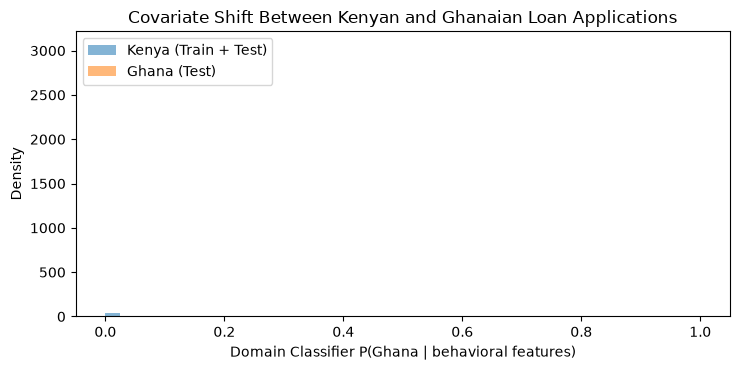

In [3]:
summary_by_slice = (
    df.assign(amount_usd=np.expm1(df["log_amount_usd"]))
    .groupby(["split", "country_id"])
    .agg(
        rows=("ID", "count"),
        median_amount_usd=("amount_usd", "median"),
        mean_duration=("duration", "mean"),
        new_borrower_pct=("is_new_borrower", lambda s: float(s.mean() * 100.0)),
        median_past_loans=("n_past_loans", "median"),
        mean_inflation=("macro_inflation", "mean"),
    )
    .round(2)
)
display(summary_by_slice)

dom_behav = run_domain_classifier(df, include_categoricals=False, include_macro=False)
dom_full = run_domain_classifier(df, include_categoricals=True, include_macro=True)

print(f"Behavioral-only Kenya vs Ghana domain ROC-AUC: {dom_behav['domain_roc_auc']:.4f}")
print(f"Full-feature (incl. macro + lender/type) domain ROC-AUC: {dom_full['domain_roc_auc']:.4f}")
display(dom_behav["top_shift_drivers"].head(10).round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
is_gh = (df["country_id"] == "Ghana").to_numpy()
ax.hist(dom_behav["oof_ghana_prob"][~is_gh], bins=30, density=True, alpha=0.55, label="Kenya (Train + Test)")
ax.hist(dom_behav["oof_ghana_prob"][is_gh], bins=30, density=True, alpha=0.55, label="Ghana (Test)")
ax.set_xlabel("Domain Classifier P(Ghana | behavioral features)")
ax.set_ylabel("Density")
ax.set_title("Covariate Shift Between Kenyan and Ghanaian Loan Applications")
ax.legend()
plt.tight_layout()
plt.show()

**Evidence NkwaPay needs before trusting Ghana predictions:**
1. **Unseen category gap:** 97% of Ghana applications come from lenders unseen in Kenya and 87% use unseen loan types (`Type_3`, `Type_8`), while 0% of Ghanaian borrowers have historical repayment records in Kenya Train.
2. **Macro regime mismatch:** Ghana's 2022–2023 inflation (~31%–38%) is 4–5x Kenya's (~7.7%), making Kenya-fitted macro weights unreliable.
3. **Minimum trust protocol:** Run a capped **pilot cohort** in Ghana with human/conservative limits, collect 90 days of true repayment labels (`target`), check local calibration + PR-AUC on Ghana outcomes, and recalibrate the operating threshold before full automation.

## 3. Part D: Disaggregated Fairness Audit & Threshold Mitigation

In [4]:
# 1. Country slice on Test predictions (Kenya Test vs Ghana Test)
print("--- Country slice on Test (LightGBM, unlabeled) ---")
display(disaggregated_evaluation(test_preds_lgb, group_col="country_id", threshold=op_point["threshold"]).round(4))

# 2. Labeled Kenya OOF fairness slices (LightGBM)
train_meta = df[df["split"] == "train"][["ID", "log_amount_usd"]].copy()
oof_lgb = oof_preds["lightgbm"].merge(train_meta, on="ID", how="left")
oof_lgb["loan_size_band"] = add_loan_size_band(oof_lgb, amount_col="log_amount_usd")

for slice_col in ["is_new_borrower", "loan_size_band", "lender_id"]:
    print(f"\n--- Fairness slice: {slice_col} ---")
    display(disaggregated_evaluation(oof_lgb, group_col=slice_col, threshold=op_point["threshold"]).head(8).round(4))

--- Country slice on Test (LightGBM, unlabeled) ---


,group_col,group,n,selection_rate,decline_rate,mean_pred_prob,selection_rate_gap,disparate_impact_ratio
0,country_id,Kenya,15069,0.6539,0.3461,0.1652,0.0000,1.0000
1,country_id,Ghana,3525,0.3540,0.6460,0.3528,0.2998,0.5415



--- Fairness slice: is_new_borrower ---


,group_col,group,n,selection_rate,decline_rate,mean_pred_prob,actual_default_rate,roc_auc,pr_auc,f1,precision,recall,fnr,fpr,selection_rate_gap,disparate_impact_ratio
0,is_new_borrower,0,68087,0.6946,0.3054,0.1447,0.0167,0.8355,0.1337,0.0833,0.0440,0.8025,0.1975,0.2969,0.0000,1.0000
1,is_new_borrower,1,567,0.1499,0.8501,0.6011,0.2099,0.8266,0.5742,0.3860,0.2407,0.9748,0.0252,0.8170,0.5447,0.2158



--- Fairness slice: loan_size_band ---


,group_col,group,n,selection_rate,decline_rate,mean_pred_prob,actual_default_rate,roc_auc,pr_auc,f1,precision,recall,fnr,fpr,selection_rate_gap,disparate_impact_ratio
0,loan_size_band,Q2_Medium,17190,0.7120,0.2880,0.1420,0.0158,0.8633,0.1456,0.0881,0.0465,0.8456,0.1544,0.2791,0.0096,0.9867
1,loan_size_band,Q1_Small,17166,0.7216,0.2784,0.1345,0.0132,0.8216,0.0831,0.0671,0.0352,0.7434,0.2566,0.2722,0.0000,1.0000
2,loan_size_band,Q4_VeryLarge,17164,0.6226,0.3774,0.1825,0.0291,0.8295,0.2102,0.1201,0.0647,0.8397,0.1603,0.3635,0.0990,0.8629
3,loan_size_band,Q3_Large,17134,0.7042,0.2958,0.1346,0.0152,0.8559,0.2482,0.0799,0.0420,0.8161,0.1839,0.2878,0.0174,0.9758



--- Fairness slice: lender_id ---


,group_col,group,n,selection_rate,decline_rate,mean_pred_prob,actual_default_rate,roc_auc,pr_auc,f1,precision,recall,fnr,fpr,selection_rate_gap,disparate_impact_ratio
0,lender_id,267278,64653,0.7221,0.2779,0.1266,0.0121,0.8158,0.0726,0.0621,0.0324,0.7423,0.2577,0.2722,0.0000,1.0000
1,lender_id,251804,3542,0.1892,0.8108,0.4716,0.0892,0.6355,0.1439,0.1826,0.1013,0.9209,0.0791,0.8001,0.5330,0.2619
2,lender_id,267277,271,0.0443,0.9557,0.7230,0.2952,0.7878,0.5875,0.4661,0.3050,0.9875,0.0125,0.9424,0.6779,0.0613
3,lender_id,245684,188,0.0426,0.9574,0.7506,0.4149,0.8294,0.6708,0.6047,0.4333,1.0000,0.0000,0.9273,0.6796,0.0589


In [5]:
# Mitigation check: group-aware threshold adjustment for thin-file (new) borrowers
# Baseline: single global threshold across all applicants
base_tenure = disaggregated_evaluation(oof_lgb, group_col="is_new_borrower", threshold=op_point["threshold"])

# Mitigation: calibrated / higher review threshold for thin-file new borrowers (reducing false exclusions)
mit_df = oof_lgb.copy()
new_mask = mit_df["is_new_borrower"] == 1
mit_threshold_new = 0.50
mit_df["mitigated_approve"] = np.where(
    new_mask,
    mit_df["y_pred"] <= mit_threshold_new,
    mit_df["y_pred"] <= op_point["threshold"],
)

mit_summary = (
    mit_df.groupby("is_new_borrower")
    .agg(
        n=("ID", "count"),
        baseline_selection_rate=("y_pred", lambda s: float(np.mean(s <= op_point["threshold"]))),
        mitigated_selection_rate=("mitigated_approve", "mean"),
        actual_default_rate=("y_true", "mean"),
    )
    .round(4)
)
print("Before vs After Thin-File Threshold Mitigation:")
display(mit_summary)

Before vs After Thin-File Threshold Mitigation:


,n,baseline_selection_rate,mitigated_selection_rate,actual_default_rate
is_new_borrower,,,,
0,68087,0.6946,0.6946,0.0167
1,567,0.1499,0.3651,0.2099


## 4. World Bank Global Findex Ghana 2021: Credit Exclusion Profile

In [6]:
if C.FINDEX_CSV.exists():
    findex = pd.read_csv(C.FINDEX_CSV)

    def weighted_rate(sub: pd.DataFrame, col: str, yes_val: int = 1) -> float:
        valid = sub[col].notna() & sub["wgt"].notna()
        if not valid.any():
            return float("nan")
        s = sub.loc[valid]
        return float(np.average((s[col] == yes_val).astype(float), weights=s["wgt"]) * 100.0)

    groups = {
        "All Ghanaian adults": findex,
        "Women (female=1)": findex[findex["female"] == 1],
        "Men (female=2)": findex[findex["female"] == 2],
        "Rural (urbanicity=1)": findex[findex["urbanicity_f2f"] == 1],
        "Urban (urbanicity=2)": findex[findex["urbanicity_f2f"] == 2],
        "Poorest 40% (inc_q<=2)": findex[findex["inc_q"] <= 2],
        "Richest 60% (inc_q>=3)": findex[findex["inc_q"] >= 3],
    }
    findex_rows = []
    for label, sub in groups.items():
        findex_rows.append({
            "group": label,
            "n_unweighted": len(sub),
            "has_account_pct": weighted_rate(sub, "account"),
            "mobile_money_pct": weighted_rate(sub, "account_mob"),
            "borrowed_formally_pct": weighted_rate(sub, "fin22a"),
        })
    display(pd.DataFrame(findex_rows).round(2))
else:
    print(f"Findex file not found at {C.FINDEX_CSV}")

,group,n_unweighted,has_account_pct,mobile_money_pct,borrowed_formally_pct
0,All Ghanaian adults,1000,68.23,59.69,7.24
1,Women (female=1),465,62.58,55.00,5.61
2,Men (female=2),535,74.18,64.62,8.96
3,Rural (urbanicity=1),360,56.52,47.86,6.59
4,Urban (urbanicity=2),640,76.08,67.62,7.67
5,Poorest 40% (inc_q<=2),309,54.72,46.38,4.88
6,Richest 60% (inc_q>=3),691,77.20,68.53,8.80
